# Building Energy Consumption Prediction

**Goal:** Predict a building's **energy consumption** from its type, size, occupants, appliances, temperature and day of week.

**Dataset:** `train_energy_data.csv` (1000 rows) and `test_energy_data.csv` (100 rows)

**Approach:** One-hot encoding of categorical columns → train/validation split → StandardScaler fitted on train only → Linear Regression → evaluate → predict on the separate test file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the data

In [2]:
train = pd.read_csv("../data/train_energy_data.csv")
test = pd.read_csv("../data/test_energy_data.csv")

In [3]:
train

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17
...,...,...,...,...,...,...,...
995,Residential,14419,68,44,23.95,Weekend,3661.21
996,Industrial,12194,7,22,14.67,Weekend,3546.34
997,Commercial,39562,88,20,32.18,Weekday,5147.21
998,Residential,8348,67,37,16.48,Weekend,3244.98


## Exploratory data analysis

In [4]:
train.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1000 non-null   object 
 1   Square Footage       1000 non-null   int64  
 2   Number of Occupants  1000 non-null   int64  
 3   Appliances Used      1000 non-null   int64  
 4   Average Temperature  1000 non-null   float64
 5   Day of Week          1000 non-null   object 
 6   Energy Consumption   1000 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 54.8+ KB


In [5]:
train.describe()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption
count,1000.000,1000.000000,1000.000000,1000.000000,1000.000000
mean,25462.388,48.372000,25.606000,22.611390,4166.252570
std,14294.554,29.061972,14.105166,7.139943,933.313064
min,560.000,1.000000,1.000000,10.050000,1683.950000
25%,13169.750,22.000000,13.000000,16.475000,3509.482500
50%,25477.000,47.000000,26.000000,22.815000,4175.730000
75%,37446.250,73.250000,38.000000,28.850000,4863.850000
max,49997.000,99.000000,49.000000,34.990000,6530.600000


In [6]:
train.shape

(1000, 7)

In [7]:
train.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

In [8]:
test.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

In [9]:
X = train.drop("Energy Consumption", axis=1)
y = train["Energy Consumption"]

## Data cleaning & preprocessing

In [10]:
X=pd.get_dummies(X,drop_first=True)

In [11]:
bool_cols = X.select_dtypes(include="bool").columns
X[bool_cols] = X[bool_cols].astype(int)

In [12]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Square Footage             1000 non-null   int64  
 1   Number of Occupants        1000 non-null   int64  
 2   Appliances Used            1000 non-null   int64  
 3   Average Temperature        1000 non-null   float64
 4   Building Type_Industrial   1000 non-null   int64  
 5   Building Type_Residential  1000 non-null   int64  
 6   Day of Week_Weekend        1000 non-null   int64  
dtypes: float64(1), int64(6)
memory usage: 54.8 KB


In [13]:
X

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,0,1,0
1,44372,66,45,16.72,0,0,0
2,19255,37,17,14.30,1,0,1
3,13265,14,41,32.82,0,1,0
4,13375,26,18,11.92,0,0,0
...,...,...,...,...,...,...,...
995,14419,68,44,23.95,0,1,1
996,12194,7,22,14.67,1,0,1
997,39562,88,20,32.18,0,0,0
998,8348,67,37,16.48,0,1,1


In [14]:
test = pd.get_dummies(test, drop_first=True)

In [15]:
bool_cols = test.select_dtypes(include="bool").columns
test[bool_cols] = test[bool_cols].astype(int)

In [16]:
test

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,24563,15,4,28.52,2865.57,0,1,0
1,27583,56,23,23.07,4283.80,0,0,1
2,45313,4,44,33.56,5067.83,0,0,0
3,41625,84,17,27.39,4624.30,0,1,1
4,36720,58,47,17.08,4820.59,0,1,0
...,...,...,...,...,...,...,...,...
95,1161,81,11,15.45,3010.81,0,0,1
96,37943,50,23,21.73,4248.49,0,1,1
97,1558,27,29,16.86,2843.60,0,0,1
98,2145,56,12,11.77,3348.39,1,0,1


## Feature distributions

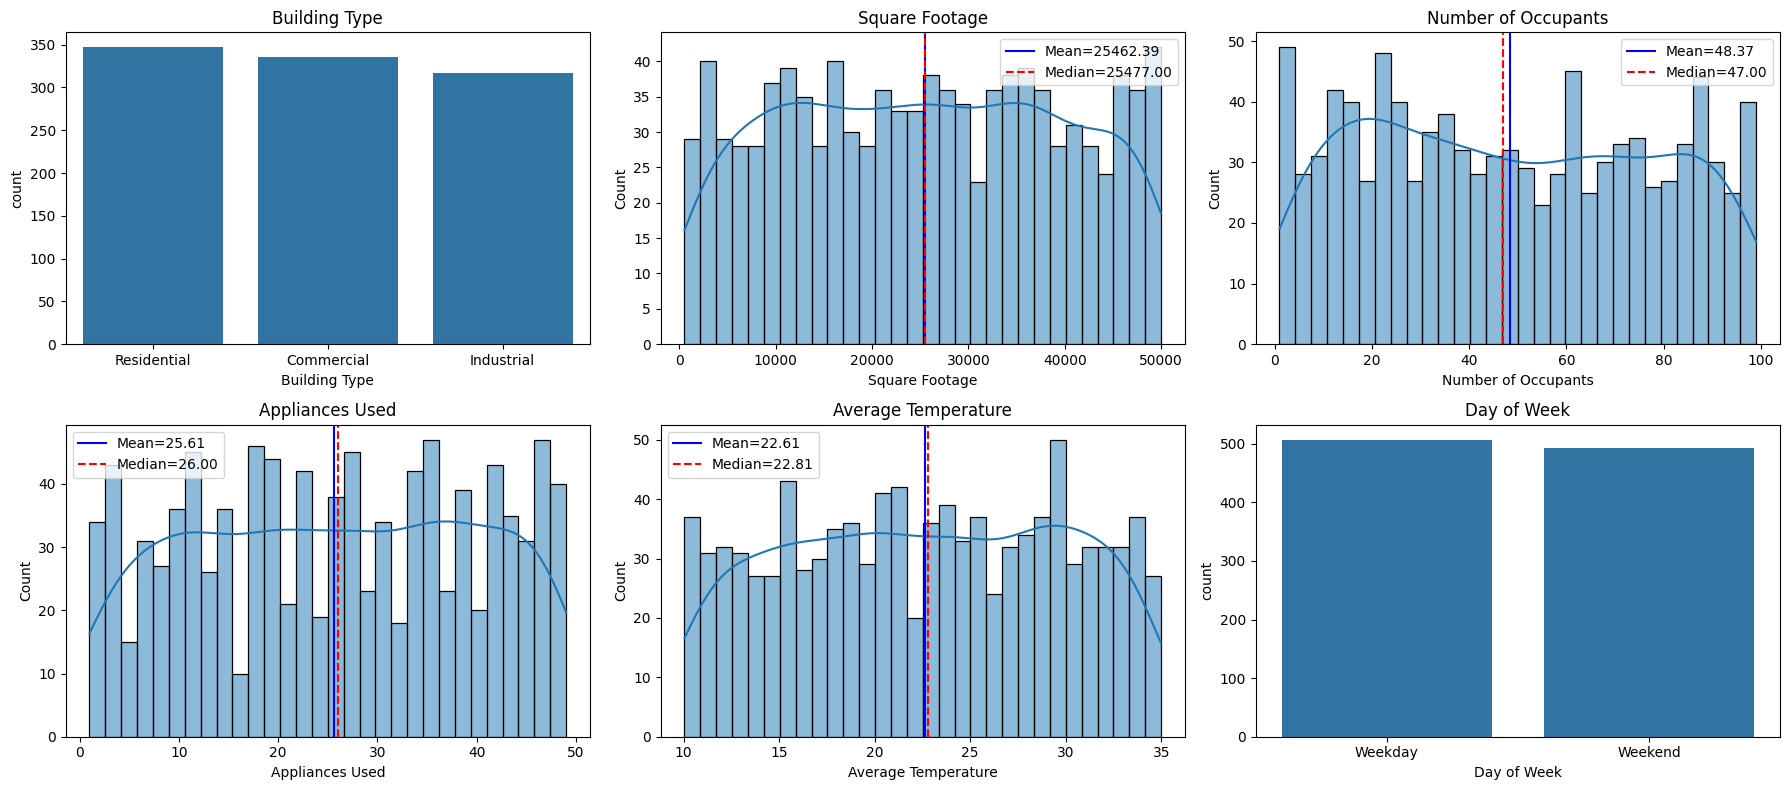

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/train_energy_data.csv")

features = df.drop("Energy Consumption", axis=1).columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):

    if df[col].dtype == "object":
        sns.countplot(data=df, x=col, ax=axes[i])
    else:
        sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i])

        mean_val = df[col].mean()
        median_val = df[col].median()

        axes[i].axvline(mean_val, color="blue", linestyle="-", label=f"Mean={mean_val:.2f}")
        axes[i].axvline(median_val, color="red", linestyle="--", label=f"Median={median_val:.2f}")

        axes[i].legend()

    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [18]:
X

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,0,1,0
1,44372,66,45,16.72,0,0,0
2,19255,37,17,14.30,1,0,1
3,13265,14,41,32.82,0,1,0
4,13375,26,18,11.92,0,0,0
...,...,...,...,...,...,...,...
995,14419,68,44,23.95,0,1,1
996,12194,7,22,14.67,1,0,1
997,39562,88,20,32.18,0,0,0
998,8348,67,37,16.48,0,1,1


## Train / test split

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=.2,shuffle=True,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)

print(y_test.shape)

(800, 7)
(200, 7)
(800,)
(200,)


## Feature scaling

In [20]:
from sklearn.preprocessing import StandardScaler
st = StandardScaler()
cols = [
    'Square Footage',
    'Appliances Used',
    'Number of Occupants',
    'Average Temperature'
]

X_train[cols] = st.fit_transform(X_train[cols])
X_test[cols] = st.transform(X_test[cols])

In [21]:
X

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,0,1,0
1,44372,66,45,16.72,0,0,0
2,19255,37,17,14.30,1,0,1
3,13265,14,41,32.82,0,1,0
4,13375,26,18,11.92,0,0,0
...,...,...,...,...,...,...,...
995,14419,68,44,23.95,0,1,1
996,12194,7,22,14.67,1,0,1
997,39562,88,20,32.18,0,0,0
998,8348,67,37,16.48,0,1,1


In [22]:
from sklearn.linear_model import LinearRegression

## Model training

In [23]:
lr=LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
y_pred=lr.predict(X_test)

## Evaluation

In [25]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE =", mse)
print("R2 Score =", r2)

MSE = 0.00018855085578872572
R2 Score = 0.9999999997684504


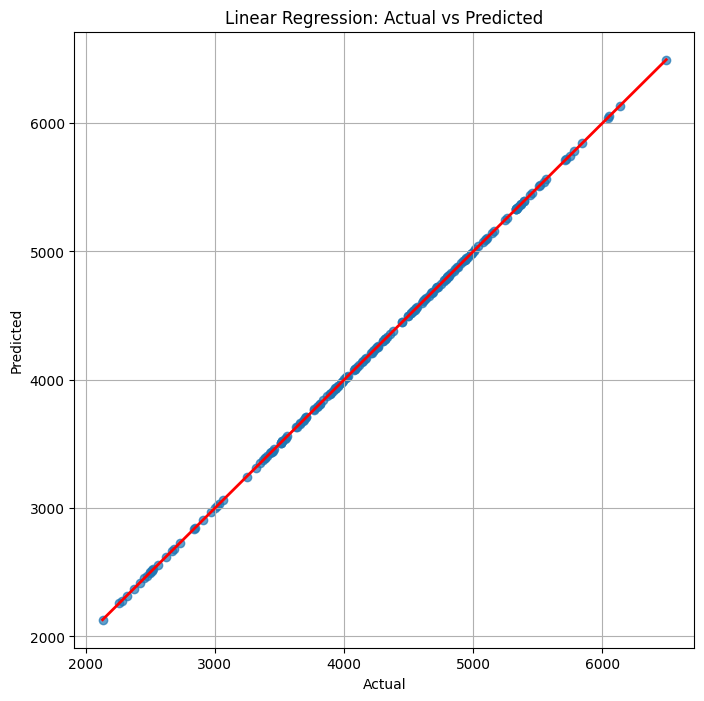

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression: Actual vs Predicted")

plt.grid(True)
plt.show()

In [27]:
test = test.drop("Energy Consumption", axis=1)

In [28]:
test[cols] = st.transform(test[cols])

pred = lr.predict(test)

In [29]:
print(pred[:10])

[2865.54919472 4283.79940731 5067.84908876 4624.2983363  4820.60111582
 5026.25054677 4404.54904558 2394.34990331 3969.09936227 5136.70214981]


## Results & conclusion

* R² ≈ **1.0** (MSE ≈ 0.0002) on the validation split.
* Such a perfect score means the target in this dataset is (almost) an exact linear function of the features – the data is synthetic. On real-world data a score like this would be a red flag for data leakage, so it is worth checking.
* The trained model and the train-fitted scaler are then applied to the separate test file.